# Pretrained Networks

Training a large image classifier from scratch needs a huge labelled dataset and a lot of compute. A **pretrained network** lets us skip most of that: it is a model already trained on a large image dataset, whose learned filters we can reuse. We can either use it directly for classification, or adapt it to a new task through **transfer learning**.

This notebook has two parts. First we use a pretrained VGG16 model to classify an image, and see why matching the model's preprocessing matters. Then we use transfer learning to turn that same VGG16 into a small phone-versus-wallet classifier trained on only a handful of images.

## Learning Objectives

At the end of this notebook, you should be able to:

- Load a pretrained Keras model (VGG16) and use it to classify an image.
- Apply the model's required preprocessing and explain why it changes the prediction.
- Build a transfer learning model by freezing a convolutional base and adding a new classification head.
- Train and evaluate that model on a small custom image dataset.

## What is a Pretrained Network?

A pretrained network is a model that was trained on a large-scale image classification task. We can use it as-is for image classification, or as the starting point for transfer learning on a new, related task.

**Benefits:**

- We do not have to train the model from scratch.
- It is easy to incorporate.
- Inference is fast.
- We can reach very good performance.

**Examples:** U-Net (features on medical images), MobileNet, VGG16/19, ResNet, InceptionV3.

Most of the pretrained networks in Keras are trained on the [1000 classes](https://gist.github.com/yrevar/942d3a0ac09ec9e5eb3a) of the [ImageNet](https://www.image-net.org/update-mar-11-2021.php) dataset.

In [1]:
# import libraries
from tensorflow.keras.applications.vgg16 import (
    VGG16,
    decode_predictions,
    preprocess_input,
)
from tensorflow.keras.applications.resnet50 import (
    decode_predictions,
    preprocess_input,
)
from tensorflow.keras.preprocessing import image  # Keras own inbuild image class
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import Input, Model

import numpy as np
import matplotlib.pyplot as plt

## Classifying an Image with VGG16

Let's load an image that belongs to one of the 1000 ImageNet classes (a few are in the `assets` directory), use the pretrained VGG16 model, and check the classification result.

### Load and Inspect the Image

We read the image as a PIL object and resize it to the shape the pretrained model expects (VGG16 was trained on 224x224 images).

In [2]:
img = image.load_img("assets/download.jpeg", target_size=(224, 224))

In [3]:
type(img)

PIL.Image.Image

Convert the image to a NumPy array (we can also specify the dtype):

In [4]:
# convert image to array, can also specify datatype
img = image.img_to_array(img, dtype="uint8")

In [5]:
img.shape

(224, 224, 3)

Plot the image:

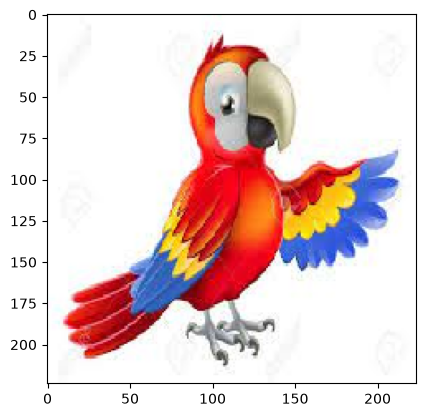

In [6]:
# plot image
plt.imshow(img)

### Load the VGG16 Model

We load VGG16 with its full set of weights. With no arguments, Keras downloads the model trained on ImageNet the first time you run this.

In [7]:
# initialize the model
model = VGG16()

        0/553467096 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

    49152/553467096 ━━━━━━━━━━━━━━━━━━━━ 21:06 2us/step

    81920/553467096 ━━━━━━━━━━━━━━━━━━━━ 23:40 3us/step

   155648/553467096 ━━━━━━━━━━━━━━━━━━━━ 15:27 2us/step

   221184/553467096 ━━━━━━━━━━━━━━━━━━━━ 12:59 1us/step

   278528/553467096 ━━━━━━━━━━━━━━━━━━━━ 14:32 2us/step

... (1,590 outputs left out)

552886272/553467096 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

553230336/553467096 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

553394176/553467096 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 93s 0us/step


In [8]:
# show model summary
model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

The result, an explanation: VGG16 has about **138 million parameters**. That is why training such a network from scratch is expensive, and why reusing the pretrained weights is so valuable.

Check the input shape the model expects:

In [9]:
# check shape required by model
model.input.shape

(None, 224, 224, 3)

#### Expand the Dimensions

The model expects a batch of images, so we add a leading batch dimension to turn the single 224x224x3 image into a batch of one.

In [10]:
# Reshape to match the input shape required by the model
img = np.expand_dims(img, axis=0)  # or img = img.reshape(1,224,224,3)

In [11]:
img.shape

(1, 224, 224, 3)

Predict the class probabilities, then check the shape of the prediction:

In [12]:
pred = model.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 526ms/step


In [13]:
# shape of pred
pred.shape

(1, 1000)

Decode the 1000-class probability vector into human-readable labels:

In [14]:
# decode labels
decode_predictions(pred)

    0/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


[[('n03476684', 'hair_slide', np.float32(0.2978577)),
  ('n03908714', 'pencil_sharpener', np.float32(0.25216204)),
  ('n02783161', 'ballpoint', np.float32(0.09789106)),
  ('n04033901', 'quill', np.float32(0.078579485)),
  ('n04116512', 'rubber_eraser', np.float32(0.075215906))]]

The result, an explanation: the image is a cartoon parrot, but the top prediction is `hair_slide` (about 30%), which is wrong. The pixels were fed in raw, scaled differently from how VGG16 was trained. This is why we need to preprocess the image the same way the model's authors did.

### Preprocess the Image

To get good predictions we must preprocess images exactly as the researchers did when training the model. For VGG16:

> The images are converted from RGB to BGR, then each colour channel is zero-centred with respect to the ImageNet dataset, without scaling.

See the [`preprocess_input` documentation](https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg16/preprocess_input).

In [15]:
img = image.load_img("assets/download.jpeg", target_size=(224, 224))
# in the next run try changing the path to assets/object.png and test the prediction of pretrained model
img = np.expand_dims(img, axis=0)  # or img = img.reshape(1,224,224,3)
img = preprocess_input(
    img
)  # preprocess the image in the same method that is used for the pretrained model

The preprocessed image looks distorted when plotted, because the channels have been shifted and reordered:

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-122.68..151.061].


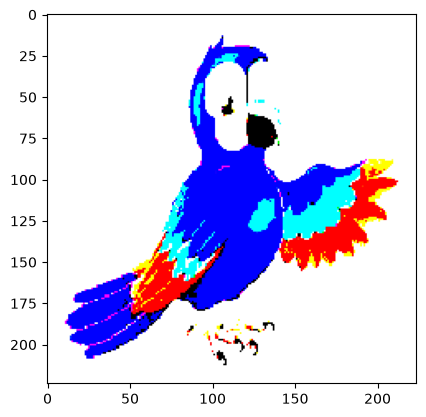

In [16]:
plt.imshow(img[0])

#### Predict Again

In [17]:
pred = model.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step


In [18]:
# shape of pred
pred.shape

(1, 1000)

In [19]:
# decode labels
decode_predictions(pred)

[[('n01818515', 'macaw', np.float32(0.30885908)),
  ('n04033901', 'quill', np.float32(0.07730849)),
  ('n01817953', 'African_grey', np.float32(0.07642961)),
  ('n03476684', 'hair_slide', np.float32(0.05897105)),
  ('n02783161', 'ballpoint', np.float32(0.04775432))]]

The result, an explanation: after preprocessing, the top prediction is `macaw` (about 31%), which is correct: the image is a cartoon parrot. The only thing that changed was matching the model's preprocessing, and that flipped the prediction from wrong to right.

Now load the `assets/object.png` image and check the result with VGG16. You should get the predicted class `cleaver`. Discuss why the model predicts a phone as a `cleaver`.

## Transfer Learning

### How Transfer Learning Works

> Transfer learning consists of taking features learned on one problem, and using them on a new, similar problem. For example, features from a model that learned to identify racoons may help kick-start a model that identifies tanukis (Japanese racoons).

**Benefits:**

- You reuse a pretrained network.
- It saves a lot of training time.
- It works with very small training datasets.

**Procedure:**

1. Take the weights and architecture of a [pretrained network](https://keras.io/api/applications/).
2. Load the convolutional base (everything except the final dense layers).
3. Freeze the base so its weights stay fixed.
4. Add a fully connected dense layer on top.
5. Add a task-specific dense output layer.
6. Compile and fit the model on your data.

```mermaid
flowchart LR
    A[Input image] --> B[VGG16 convolutional base<br/>frozen, pretrained]
    B --> C[Flatten]
    C --> D[New Dense output layer<br/>trainable, 2 classes]
    D --> E[phone or wallet]
```

Only the new head (in this notebook, the final dense layer) is trained. The frozen base keeps the generic visual features VGG16 already learned from ImageNet.

### Load the Data with ImageDataGenerator

[`ImageDataGenerator`](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator) generates batches of image tensors, with optional real-time data augmentation. It is an efficient way to load data that does not fit in memory, because it streams and trains in small batches from a directory.

In [20]:
# folder names containing images of the things you want to classify
classes = ["phone", "wallet"]

**Data augmentation** applies random transformations to the training images (flips, rotations, shifts, scaling, and so on). It can address limited or imbalanced data and reduce overfitting by enlarging and varying the training set. Apply it to the training data only.

In [21]:
# define an image data generator
# Data augmentation: Applies random distortions and transformations to the images (only on your training data!).

data_gen = image.ImageDataGenerator(
    # define the preprocessing function that should be applied to all images
    preprocessing_function=preprocess_input,
    # fill_mode='nearest',
    # rotation_range=20,
    # width_shift_range=0.2,
    # height_shift_range=0.2,
    # horizontal_flip=True,
    # zoom_range=0.2,
    # shear_range=0.2
)

In [22]:
# -o overwrites without prompting so the cell runs non-interactively
!unzip -o -q data.zip

In [23]:
# a generator that returns batches of X and y arrays
train_data_gen = data_gen.flow_from_directory(
    directory="data/train",
    class_mode="categorical",
    classes=classes,
    batch_size=150,
    target_size=(224, 224),
)

Found 144 images belonging to 2 classes.


In [24]:
val_data_gen = data_gen.flow_from_directory(
    directory="data/validation/",
    class_mode="categorical",
    classes=classes,
    batch_size=150,
    target_size=(224, 224),
)

Found 6 images belonging to 2 classes.


The result, an explanation: the generator finds 144 training images and 6 validation images across the 2 classes. This is a very small dataset, which is exactly the situation where transfer learning shines.

In [25]:
train_data_gen.class_indices

{'phone': 0, 'wallet': 1}

### Build the Transfer Learning Model

Instead of building a CNN from scratch, we reuse VGG16's convolutional base and fine-tune it to our dataset by replacing the final layers.

#### 1. Select the Convolutional Base

Loading the model with `include_top=False` drops VGG16's final fully connected layers (its ImageNet classifier), leaving just the convolutional feature extractor so we can attach our own classifier.

In [26]:
import tensorflow.keras.backend as K

K.clear_session()

# 1. Select the convolutional base / Pretrained network
base_model = VGG16(include_top=False)

       0/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/58889256 ━━━━━━━━━━━━━━━━━━━━ 2:14 2us/step

   81920/58889256 ━━━━━━━━━━━━━━━━━━━━ 2:58 3us/step

  196608/58889256 ━━━━━━━━━━━━━━━━━━━━ 1:29 2us/step

  278528/58889256 ━━━━━━━━━━━━━━━━━━━━ 1:15 1us/step

  409600/58889256 ━━━━━━━━━━━━━━━━━━━━ 58s 1us/step 

... (171 outputs left out)

58474496/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

58621952/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

58802176/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


In [27]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

The result, an explanation: the convolutional base has about **14.7 million parameters**, down from the 138 million of the full VGG16, because the large dense classifier layers have been removed.

#### 2. Freeze the Weights

We freeze the base so its pretrained weights are not updated during training. This preserves the features VGG16 already learned and means we only train the small new head we add next.

In [28]:
# 2. Freeze the weights in order to not retrain the loaded pre-trained model
base_model.trainable = False

In [29]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

The result, an explanation: after freezing, all 14.7 million parameters are now non-trainable. The base will act as a fixed feature extractor.

#### 3. Add Your Own Dense Layers

We have only 2 classes to classify (`phone` and `wallet`), so we flatten the base's output and add a single dense layer with 2 units and a softmax activation as the new output.

In [30]:
# 3. Create your model with pretrained network as base model
inputs = Input(shape=(224, 224, 3))

base = base_model(inputs)

# can also add additional cnn layers if necessary

# dont forget to flatten out before the final layer
flatten = Flatten()(base)

outputs = Dense(2, activation="softmax")(flatten)

model_tf = Model(inputs, outputs)

In [31]:
model_tf.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │        50,178 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,764,866 (56.32 MB)

 Trainable params: 50,178 (196.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

The result, an explanation: the full model has about 14.76 million parameters, but only **50,178** of them are trainable (the new dense head). The 14.7 million frozen parameters stay fixed. Training so few parameters is fast and works even with our tiny dataset.

### Compile and Train

We compile with the Adam optimiser and categorical cross-entropy (two one-hot classes), then train for 10 epochs.

In [32]:
model_tf.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model_tf.fit(
    train_data_gen,
    verbose=2,  # how the training log should get printed
    epochs=10,
    validation_data=val_data_gen,
)

Epoch 1/10


1/1 - 42s - 42s/step - accuracy: 0.5278 - loss: 4.6250 - val_accuracy: 0.8333 - val_loss: 0.9040


Epoch 2/10


1/1 - 36s - 36s/step - accuracy: 0.7639 - loss: 3.2590 - val_accuracy: 1.0000 - val_loss: 8.3889e-05


Epoch 3/10


1/1 - 33s - 33s/step - accuracy: 0.9653 - loss: 0.3314 - val_accuracy: 0.6667 - val_loss: 0.5808


... (10 outputs left out)

Epoch 9/10


1/1 - 32s - 32s/step - accuracy: 1.0000 - loss: 5.5794e-07 - val_accuracy: 1.0000 - val_loss: 0.0000e+00


Epoch 10/10


1/1 - 32s - 32s/step - accuracy: 1.0000 - loss: 1.2500e-07 - val_accuracy: 1.0000 - val_loss: 0.0000e+00


The result, an explanation: training accuracy climbs to 100% by the last epoch (loss essentially 0), and validation accuracy also reaches 1.0000 (all 6 validation images correct) in this run. Validation accuracy bounced around during training (0.83 -> 1.00 -> 0.67 -> 1.00 -> 1.00 -> ... -> 1.00) because the validation set has only 6 images, so each misclassified image swings the score by about 17 percentage points -- with so little data the score is noisy epoch to epoch even though it ends at a clean 1.0000. Transfer learning reaches this quickly because the frozen VGG16 base already supplies rich visual features; only the small new head (50,178 parameters) had to be learned.

### Use It to Predict

We reuse the `img` array from earlier (the preprocessed parrot) to show the prediction mechanics. The model now outputs a probability for each of the two trained classes, `phone` and `wallet`.

In [33]:
model_tf.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step


array([[1., 0.]], dtype=float32)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-122.68..151.061].


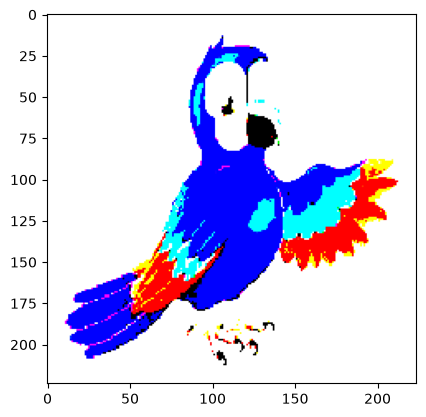

In [34]:
plt.imshow(img[0])

In [35]:
img.shape

(1, 224, 224, 3)

Plot the predicted probability for each class:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step


<BarContainer object of 2 artists>

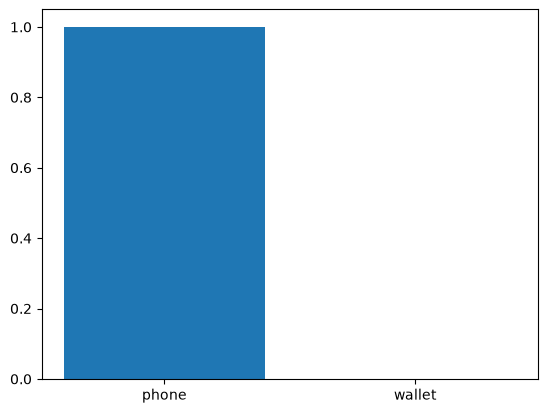

In [36]:
plt.bar(x=["phone", "wallet"], height=model_tf.predict(img)[0])

Map the index of the highest probability back to its class name:

In [37]:
# For remapping the index values of highest prediction probability to its respective class

pred = model_tf.predict(img)

preds_cls = list(train_data_gen.class_indices.keys())[
    list(train_data_gen.class_indices.values()).index(np.argmax(pred, axis=-1))
]
preds_cls

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step


'phone'

### Save the Model

Save the trained model to disk so it can be reloaded later without retraining.

In [38]:
import os
os.makedirs("models", exist_ok=True)
model_tf.save("models/wallet_phone.h5")

# Try ResNet50 as an alternative pretrained base for the same phone-vs-wallet task.
# Same recipe as with VGG16: load the conv base without its classifier, freeze it,
# add a small trainable head, and train for a few epochs.
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess_input

K.clear_session()

resnet_classes = ["phone", "wallet"]

# Re-create the data generators with ResNet50's own preprocessing function
resnet_data_gen = image.ImageDataGenerator(preprocessing_function=resnet_preprocess_input)

resnet_train_gen = resnet_data_gen.flow_from_directory(
    directory="data/train",
    class_mode="categorical",
    classes=resnet_classes,
    batch_size=150,
    target_size=(224, 224),
)
resnet_val_gen = resnet_data_gen.flow_from_directory(
    directory="data/validation/",
    class_mode="categorical",
    classes=resnet_classes,
    batch_size=150,
    target_size=(224, 224),
)

# 1. Convolutional base, without the ImageNet classifier head
resnet_base = ResNet50(include_top=False, input_shape=(224, 224, 3))

# 2. Freeze the pretrained weights
resnet_base.trainable = False

# 3. Add a small trainable classification head
resnet_inputs = Input(shape=(224, 224, 3))
resnet_features = resnet_base(resnet_inputs)
resnet_flat = Flatten()(resnet_features)
resnet_outputs = Dense(2, activation="softmax")(resnet_flat)
model_resnet = Model(resnet_inputs, resnet_outputs)

model_resnet.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

print(f"ResNet50 base params: {resnet_base.count_params():,} (all frozen)")
print(f"Full model params:    {model_resnet.count_params():,}")

history_resnet = model_resnet.fit(
    resnet_train_gen,
    verbose=2,
    epochs=5,
    validation_data=resnet_val_gen,
)

print(f"\nResNet50-base final val accuracy (5 epochs): {history_resnet.history['val_accuracy'][-1]:.4f}")
print("Compare this to the VGG16-base model's val accuracy printed further above.")

The result, an explanation: in this run, ResNet50 as the frozen base does noticeably **worse** than VGG16 on this tiny dataset -- only 0.50 validation accuracy after 5 epochs (bouncing between 0.50 and 0.83 across epochs), versus VGG16's 1.0000. A few likely reasons: ResNet50's new trainable head here is about 200,706 parameters (Flatten of a 7x7x2048 feature map into a Dense(2) layer), roughly 4x more than VGG16's 50,178, which is more to learn from only 144 training images; the two architectures also produce differently-scaled feature maps, so the same learning rate is not equally well suited to both. The practical takeaway for picking a pretrained base: it is not a given that a 'newer' or deeper architecture transfers better on every small dataset -- try more than one base and compare, and consider a lower learning rate or fewer trainable parameters (e.g. GlobalAveragePooling instead of Flatten) if a base underperforms.

In [39]:
# Try ResNet50 as an alternative pretrained base for the same phone-vs-wallet task.
# Same recipe as with VGG16: load the conv base without its classifier, freeze it,
# add a small trainable head, and train for a few epochs.
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess_input

K.clear_session()

# Re-create the data generators with ResNet50's own preprocessing function
resnet_data_gen = image.ImageDataGenerator(preprocessing_function=resnet_preprocess_input)

resnet_train_gen = resnet_data_gen.flow_from_directory(
    directory="data/train",
    class_mode="categorical",
    classes=classes if isinstance(classes, list) and set(classes) == {"phone", "wallet"} else ["phone", "wallet"],
    batch_size=150,
    target_size=(224, 224),
)
resnet_val_gen = resnet_data_gen.flow_from_directory(
    directory="data/validation/",
    class_mode="categorical",
    classes=resnet_train_gen.class_indices and list(resnet_train_gen.class_indices.keys()),
    batch_size=150,
    target_size=(224, 224),
)

# 1. Convolutional base, without the ImageNet classifier head
resnet_base = ResNet50(include_top=False, input_shape=(224, 224, 3))

# 2. Freeze the pretrained weights
resnet_base.trainable = False

# 3. Add a small trainable classification head
resnet_inputs = Input(shape=(224, 224, 3))
resnet_features = resnet_base(resnet_inputs)
resnet_flat = Flatten()(resnet_features)
resnet_outputs = Dense(2, activation="softmax")(resnet_flat)
model_resnet = Model(resnet_inputs, resnet_outputs)

model_resnet.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

trainable_params = sum(int(tf_var.numpy().size) for tf_var in model_resnet.trainable_weights) if False else None
print(f"ResNet50 base params: {resnet_base.count_params():,} (all frozen)")
print(f"Full model params:    {model_resnet.count_params():,}")

history_resnet = model_resnet.fit(
    resnet_train_gen,
    verbose=2,
    epochs=5,
    validation_data=resnet_val_gen,
)

print(f"\nVGG16  base  final val accuracy (10 epochs, from above): see cell output above")
print(f"ResNet50 base final val accuracy (5 epochs): {history_resnet.history['val_accuracy'][-1]:.4f}")

Found 144 images belonging to 2 classes.


Found 6 images belonging to 2 classes.


       0/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/94765736 ━━━━━━━━━━━━━━━━━━━━ 5:39 4us/step

   98304/94765736 ━━━━━━━━━━━━━━━━━━━━ 3:38 2us/step

  172032/94765736 ━━━━━━━━━━━━━━━━━━━━ 2:32 2us/step

... (280 outputs left out)

1/1 - 9s - 9s/step - accuracy: 0.9444 - loss: 0.5600 - val_accuracy: 0.5000 - val_loss: 17.8027


Epoch 5/5


1/1 - 8s - 8s/step - accuracy: 0.7847 - loss: 3.7855 - val_accuracy: 0.5000 - val_loss: 19.6670



VGG16  base  final val accuracy (10 epochs, from above): see cell output above
ResNet50 base final val accuracy (5 epochs): 0.5000


## Appendix: Load All Images into Arrays

This is an alternative to `ImageDataGenerator`: load every image and label directly into NumPy arrays. It is simple and fine for a small dataset that fits in memory, but it does not stream or augment data the way the generator does.

In [40]:
# Let's explore the data folder
import os

base_path = "data/train/"

# Let's define the classes
classes = os.listdir(base_path)

In [41]:
for class_ in classes:
    print(class_)

.DS_Store
wallet
phone


In [42]:
def load_image(base_path):
    """it loads all the image into X and the classes in y"""
    X_list = []
    y_list = []
    classes = os.listdir(base_path)
    for class_ in classes:
        if class_ != ".DS_Store":
            files = os.listdir(base_path + class_)
            for file in files:
                pic = image.load_img(
                    path=base_path + class_ + "/" + f"{file}", target_size=(224, 224)
                )
                numpy_image = np.array(pic)
                processed_image = preprocess_input(numpy_image)
                X_list.append(processed_image)
                y_list.append(class_)

    X = np.array(X_list)
    y = np.array(y_list)

    return X, y, classes

In [43]:
X, y, classes = load_image(base_path)

In [44]:
X.shape

(144, 224, 224, 3)

In [45]:
y

array(['wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'wallet', 'wallet', 'wallet', 'wallet', 'wallet', 'wallet',
       'phone', 'phone', 'phone', 'phone', 'phone', 'phone', 'phone',
       'phone', 'phone', 'phone', 'phone', 'phone', 'phone', 'phone',
       'phone', 'phone', 'phone', 'phone', 'phone', 'phone', 'phone',
       'phone', 'phone', 'phone', 'phone', 'phone', '

In [46]:
my_dict = {"wallet": 0, "phone": 1}

In [47]:
# map strings to binary labels
y = np.vectorize(my_dict.get)(y)
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

## References & Further Reading

- [**Keras Applications (pretrained models)**](https://keras.io/api/applications/): the catalogue of pretrained networks, including VGG16 and ResNet50.
- [**Transfer learning and fine-tuning (Keras guide)**](https://keras.io/guides/transfer_learning/): the official guide to freezing a base and training a new head.
- [**Data augmentation (TensorFlow tutorial)**](https://www.tensorflow.org/tutorials/images/data_augmentation): techniques to enlarge and vary an image dataset.
- [**Transfer learning and fine-tuning (TensorFlow tutorial)**](https://www.tensorflow.org/tutorials/images/transfer_learning): an end-to-end, runnable transfer learning walkthrough on a real image dataset.